In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Global settings**

In [ ]:
# @title Paths and global constant definitions

# Paths
import os
# Create directories if they don't exist
os.makedirs('/content/drive/MyDrive/CHALLENGE 1/models/', exist_ok=True)
os.makedirs('/content/drive/MyDrive/CHALLENGE 1/logs/', exist_ok=True)
os.makedirs('/content/drive/MyDrive/CHALLENGE 1/submissions/', exist_ok=True)

main_directory_path = "/content/drive/MyDrive/CHALLENGE 1"

data_dir = main_directory_path + "/PiratePainDataset/"
models_dir = main_directory_path + "/models/"
logs_dir = main_directory_path + "/logs/"
submission_dir = main_directory_path + "/submissions/"

# Constants
num_classes = 3
best_model = None
best_performance = float('-inf')

SEED = 42

In [ ]:
# Set environment variables before importing modules

os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Import PyTorch
import torch
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False # Disable for reproducibility
    torch.backends.cudnn.deterministic = True # Ensure deterministic operations
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import ExponentialLR
from scipy.signal import welch

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
PyTorch version: 2.8.0+cu126
Device: cuda


In [ ]:
# @title Reload model function

def reload_model(nome_modello, device,
                 input_size=37, hidden_size=64, num_layers=2,
                 num_classes=3, dropout_rate=0.2,
                 bidirectional=False, rnn_type='GRU',conv_channels=20):
    # Paths
    path_model = f"{models_dir}{nome_modello}_model.pt"
    path_history = f"{models_dir}{nome_modello}_history.pt"

    # Recreate model
    model = RecurrentClassifier(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type,
        conv_channels=conv_channels
    ).to(device)

    # Load weights
    state_dict = torch.load(path_model, map_location=device)
    model.load_state_dict(state_dict)

    # Load history
    history = torch.load(path_history, map_location=device)

    return model, history

# Data saving
from datetime import datetime
data_ora_correnti = datetime.now()

data_formattata = data_ora_correnti.strftime("%Y%m%d_%H%M%S")
print("Data e ora formattate:", data_formattata)

Data e ora formattate: 20251117_172730


In [ ]:
# @title Custom Hybrid CosineAnnealing-StepLR Scheduler

from torch.optim.lr_scheduler import _LRScheduler
import math
class IbridCosineStepLR(_LRScheduler):
    def __init__(self, optimizer, T_max = 4, step_size=10, gamma=0.1, eta_min=1e-4, amplitude = 0.001, last_epoch=-1):
        """
        Combines Cosine Annealing with Step decay (StepLR).

        Args:
            T_max: Number of epochs for a full cosine cycle.
            step_size: Interval between successive step decays.
            gamma: Multiplicative factor applied at each step decay.
            amplitude: Amplitude of the cosine component controlling LR oscillation.
            eta_min: Minimum learning rate.

        """
        self.T_max = T_max
        self.step_size = step_size
        self.gamma = gamma
        self.eta_min = eta_min
        self.amplitude = amplitude
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        step_factor = self.gamma ** (self.last_epoch // self.step_size)
        return [
            max(self.eta_min, base_lr * step_factor * (1 + self.amplitude * math.cos(math.pi * self.last_epoch / self.T_max)))
            for base_lr in self.base_lrs
        ]

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)  # probabilità del target
        focal_loss = (1 - pt) ** self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss


In [ ]:
# @title Jitter-Based Upsampling Function

def upsample_timeseries(df,label_col='pain_level',series_id_col='sample_index', balancement_proportion = 0.5, start_index=661,jitter_columns=None,jitter_std=0.1):
    """
    Upsamples minority classes and assigns a unique series index to each series.
    Adds small Gaussian noise (jitter) to specified columns when duplicating.

    Parameters:
    - df: pandas DataFrame with time series data (each series is identified by series_id_col).
    - label_col: column name for the class label.
    - series_id_col: column name for the series identifier.
    - start_index: starting index for new augmented series.
    - jitter_columns: list of columns to which Gaussian noise should be added.
    - jitter_std: standard deviation of Gaussian noise added to jitter_columns.
    - balancement_proportion: desired proportion of each minority class relative to the majority class.

    Returns:
    - upsampled_df: DataFrame with balanced classes and unique series indices.
    """

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    df = df.copy()
    df['augmented'] = False  # Flag to identify duplicated series

    if jitter_columns is None:
        # Default to joint columns
        jitter_columns = [f'joint_{str(i).zfill(2)}' for i in range(30)]

    # Get unique series IDs and their corresponding labels
    unique_series_labels = df.groupby(series_id_col)[label_col].first().reset_index()

    # Count how many series there are for each label
    series_counts_by_label = unique_series_labels[label_col].value_counts()
    max_series_count = int(series_counts_by_label.max()*balancement_proportion)

    upsampled_series_data_list = []
    current_new_sample_index = start_index

    np.random.seed(SEED)

    # Iterate through each unique label (class)
    for label, count in series_counts_by_label.items():
        # Get all original 'sample_index' for the current label
        original_sample_indices_for_label = unique_series_labels[unique_series_labels[label_col] == label][series_id_col].tolist()

        # Add original series data to the list
        for original_idx in original_sample_indices_for_label:
            series_data = df[df[series_id_col] == original_idx].copy()
            upsampled_series_data_list.append(series_data)

        # If this class is a minority class, duplicate series until it matches max_series_count
        if count < max_series_count:
            num_to_add = max_series_count - count
            # Randomly select series from this class to duplicate
            series_to_duplicate = np.random.choice(original_sample_indices_for_label, size=num_to_add, replace=True)

            for chosen_original_idx in series_to_duplicate:
                duplicated_series_data = df[df[series_id_col] == chosen_original_idx].copy()
                duplicated_series_data['augmented'] = True
                # Apply jitter only to specified columns
                duplicated_series_data[jitter_columns] = duplicated_series_data[jitter_columns] + \
                                                        np.random.normal(0, jitter_std, duplicated_series_data[jitter_columns].shape)
                # Assign a new unique sample_index to the duplicated series
                duplicated_series_data[series_id_col] = current_new_sample_index
                upsampled_series_data_list.append(duplicated_series_data)
                current_new_sample_index += 1

    # Concatenate all series (original and augmented) into a single DataFrame
    upsampled_df = pd.concat(upsampled_series_data_list, ignore_index=True)
    return upsampled_df


# **Exploratory data analysis**

In [ ]:
source_train = pd.read_csv(f"{data_dir}pirate_pain_train.csv")
source_label_train = pd.read_csv(f"{data_dir}pirate_pain_train_labels.csv")

In [ ]:
# Calculating the initial shape of the Data Frame
shape_0 = source_train.shape

# Remove rows with any missing values
source_train.dropna(axis=0, how='any', inplace=True)

# Calculating the shape of the DataFrame after removing rows with missing values
shape_1 = source_train.shape

if (shape_0[0] - shape_1[0] == 0):
    print(f"No missing values in the DataFrame")
else: print(f"{shape_0[0] - shape_1[0]} rows removed from the DataFrame")

# Print the shape of the DataFrame
print(f"DataFrame shape: {shape_1}")

# Display the first 10 rows of the DataFrame
source_train.head(10)

# Define column names for the dataset
column_names = ['sample_index', 'time']
column_names = column_names + [f'pain_survey_{str(i+1)}' for i in range(4)]
column_names = column_names + ['n_legs', 'n_hands', 'n_eyes']
column_names = column_names + [f'joint_{str(i).zfill(2)}' for i in range(31)]
column_names = column_names + [f'pain_level']

source_label_train = source_label_train.rename(columns={'label': 'pain_level'})

# Merge on sample_index
df = pd.merge(source_train, source_label_train[['sample_index', 'pain_level']], on='sample_index', how='left')
df = df.drop(['joint_30'], axis = 1)

# Ora X_train ha una nuova colonna 'pain_level' con l'etichetta corrispondente a ogni sample_index
print(df[['sample_index', 'pain_level']].head())


# Display a concise summary of the DataFrame
# df.head()

No missing values in the DataFrame
DataFrame shape: (105760, 40)
   sample_index pain_level
0             0    no_pain
1             0    no_pain
2             0    no_pain
3             0    no_pain
4             0    no_pain


In [ ]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0
}

# Count occurrences of each activity for unique IDs in the training set
for id in df['sample_index'].unique():
    label = df[df['sample_index'] == id]['pain_level'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 511, 'low_pain': 94, 'high_pain': 56}


## Mappings definition

Mapping of pain levels and number of legs, hands, eyes to numerical values

In [ ]:
pain_level_mapping = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2
}

legs_mapping = {
    'two': 0,
    'one+peg_leg': 1
}

hands_mapping = {
    'two': 0,
    'one+hook_hand': 1
}
eyes_mapping = {
    'two': 0,
    'one+eye_patch': 1
}

# Map activity names to integers in the training set
df['pain_level'] = df['pain_level'].map(pain_level_mapping)

# Map activity names to integers in the training set
df['n_legs'] = df['n_legs'].map(legs_mapping)

# Map activity names to integers in the training set
df['n_hands'] = df['n_hands'].map(hands_mapping)

# Map activity names to integers in the training set
df['n_eyes'] = df['n_eyes'].map(eyes_mapping)

#Convert int64 type column  to int32 data type
for column in column_names[:9]:
    df[column] = df[column].astype(np.int32)

#Convert float64 type column  to float32 data type
for column in column_names[9:39]:
    df[column] = df[column].astype(np.float32)

## **Log-scale transformation of some sensor variables**

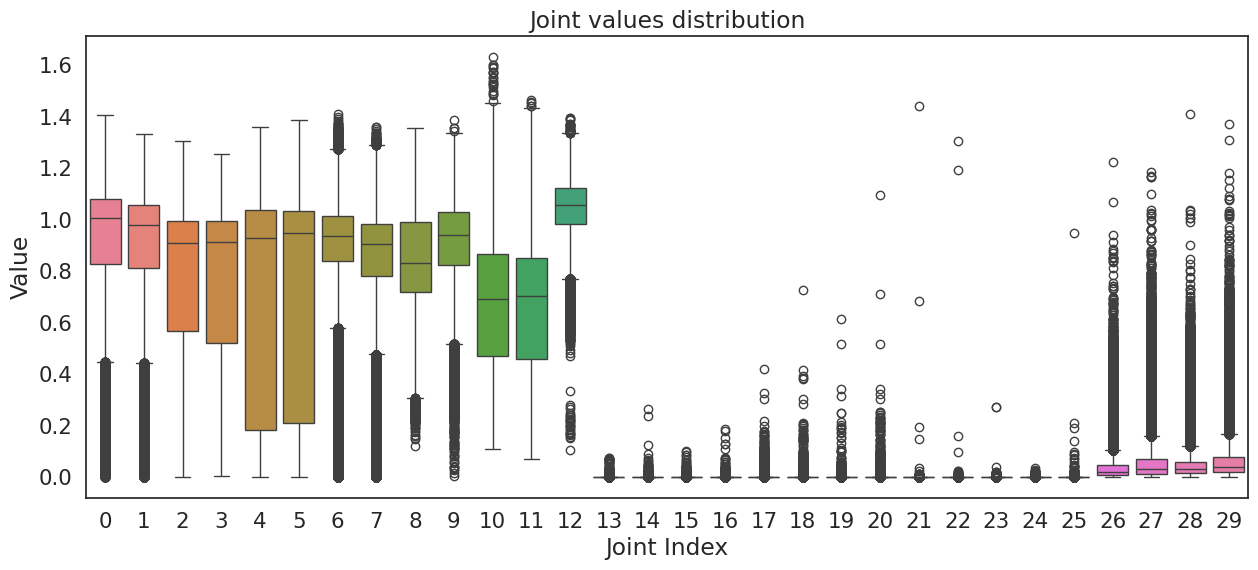

In [ ]:
# Extraction of the values associated to the joints
joints_columns = [f'joint_{str(i).zfill(2)}' for i in range(30)]
joints = np.array([df[joints_columns].values])

plt.figure(figsize=(15,6))
sns.boxplot(data = [joints[:, :, j].flatten() for j in range(joints.shape[-1])])
plt.title('Joint values distribution')
plt.xlabel('Joint Index')
plt.ylabel('Value')
plt.show()

In [ ]:
# Extraction of the values associated to the joints between 13 and 29
log_columns = [f'joint_{i}' for i in range(13, 30)]

# Log scale transformation
df[log_columns] = np.log(df[log_columns] + 1e-8)

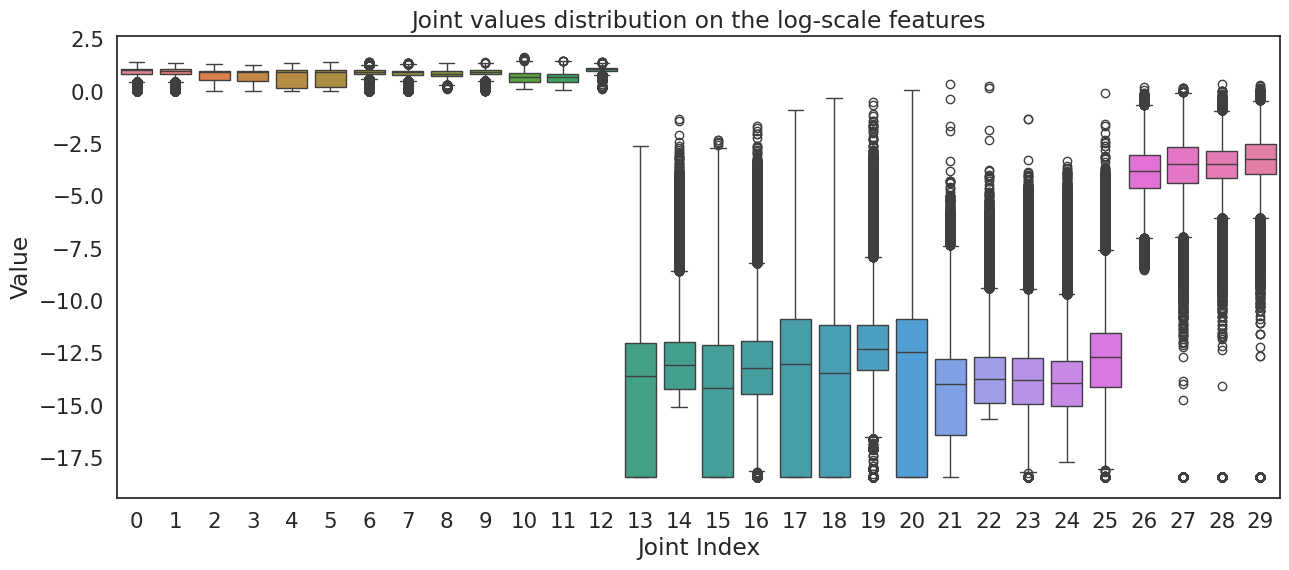

In [ ]:
# Extraction of the values associated to the joints
joints_columns = [f'joint_{str(i).zfill(2)}' for i in range(30)]
joints = np.array([df[joints_columns].values])

plt.figure(figsize=(15,6))
sns.boxplot(data = [joints[:, :, j].flatten() for j in range(joints.shape[-1])])
plt.title('Joint values distribution on the log-scale features')
plt.xlabel('Joint Index')
plt.ylabel('Value')
plt.show()



We now define some global constants relative to the input

In [ ]:
input_shape = (40, df.shape[1] - 3)
print(input_shape)

# column_names = [c for c in column_names if c not in to_remove]
print(column_names)

int_cols = ['sample_index', 'time','pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4', 'n_hands']
col_notsensors = ['sample_index', 'time','pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4', 'n_hands','n_eyes','n_legs','pain_level']
target_time_index = ['sample_index', 'time','pain_level']

(40, 37)
['sample_index', 'time', 'pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4', 'n_legs', 'n_hands', 'n_eyes', 'joint_00', 'joint_01', 'joint_02', 'joint_03', 'joint_04', 'joint_05', 'joint_06', 'joint_07', 'joint_08', 'joint_09', 'joint_10', 'joint_11', 'joint_12', 'joint_13', 'joint_14', 'joint_15', 'joint_16', 'joint_17', 'joint_18', 'joint_19', 'joint_20', 'joint_21', 'joint_22', 'joint_23', 'joint_24', 'joint_25', 'joint_26', 'joint_27', 'joint_28', 'joint_29', 'joint_30', 'pain_level']


## **Balancement and variables analysis**

In [ ]:
# Visualise the count of timestamps for each activity
def balancement_check(df):
    plt.figure(figsize=(17, 5))
    sns.countplot(
        x='pain_level',
        data=df,
        order=df['pain_level'].value_counts().index,
        palette='tab10'
    )

    # Set the title of the plot
    plt.title('Activity Timestamps')

    # Display the plot
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

def inspect_activity(df):
    samples_number = 160
    pain_levels = sorted(df['pain_level'].unique())  # es. [0, 1, 2]
    sensors = ['pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4']

    colors = ['black','blue','red','green']

    # Crea una figura con 4 righe (sensori) x 3 colonne (livelli di dolore)
    fig, axes = plt.subplots(len(sensors), len(pain_levels), figsize=(18, 10), sharex=True)

    for i, sensor in enumerate(sensors):         # righe
        for j, pain in enumerate(pain_levels):   # colonne
            ax = axes[i, j]
            data = df[df['pain_level'] == pain][sensor][:samples_number]
            ax.plot(data.values, color=colors[i])
            ax.set_title(f"{sensor} — pain {pain}", fontsize=10)
            if i == len(sensors) - 1:
                ax.set_xlabel("Sample")
            if j == 0:
                ax.set_ylabel("Value")

    plt.tight_layout()
    plt.show()


View of the class distribution in the training set

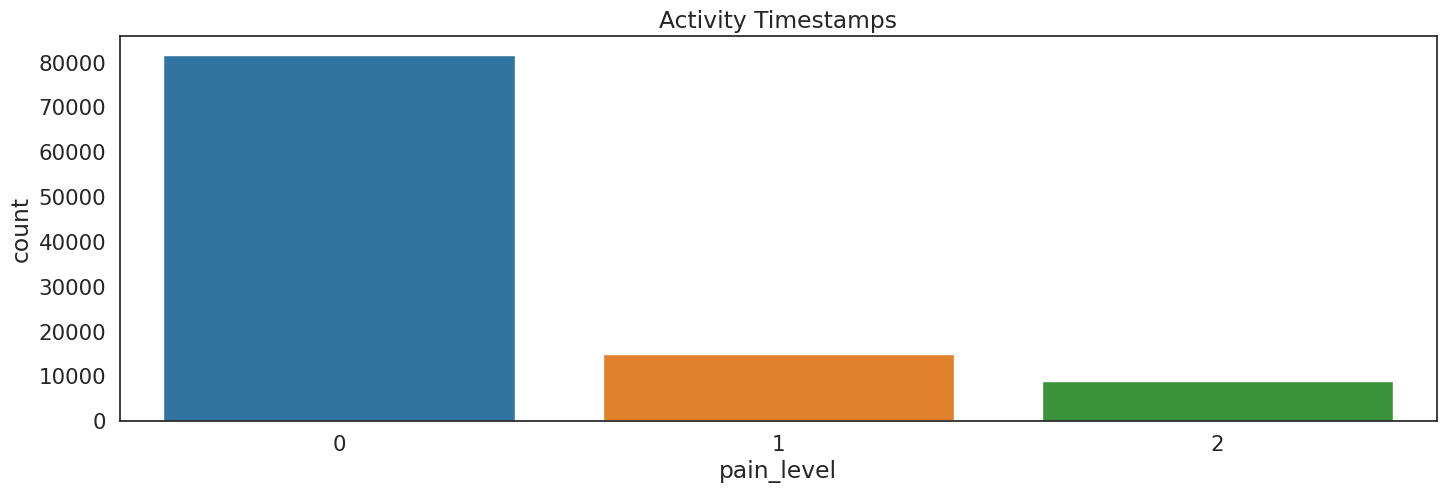

In [ ]:
balancement_check(df)

Plot of time-series for a fixed number of samples, separated by
sensor type and pain level

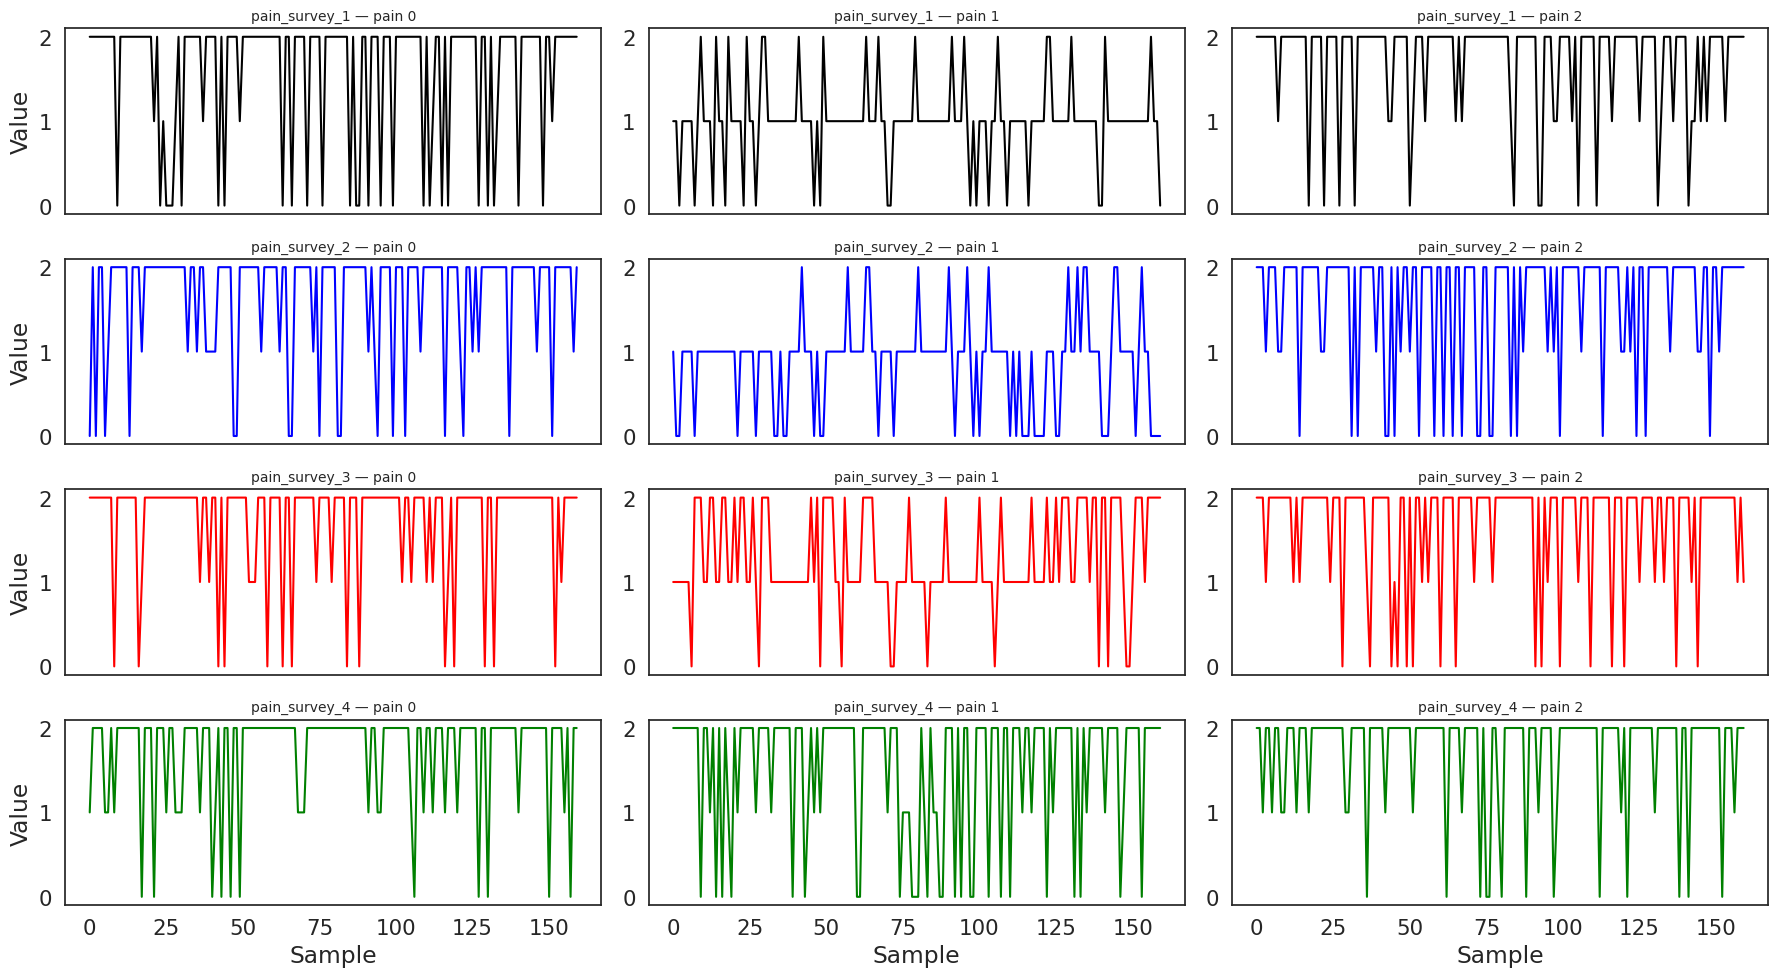

In [ ]:
inspect_activity(df)

## **Definition of data-processing functions**

Definition of PyTorch data loader


In [ ]:
# Define a function to build sequences from the dataset
def build_sequences(df, window=40, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][column_names[2:39]].values

        # Retrieve the activity label for the current ID
        label = df[df['sample_index'] == id]['pain_level'].values[0]

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        if padding_len != window:  # se temp è già divisibile per window, no padding
            padding = np.zeros((padding_len, 37), dtype='float32')
            temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [ ]:
# @title Gran-loader function

def gran_loader(df, seed = 42, n_val_users = 61, window_size = 40, stride = 5, batch_size = 64):

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    unique_users = df['sample_index'].unique()
    random.shuffle(unique_users)

    n_train_users = len(unique_users) - n_val_users

    user_labels = df.groupby('sample_index')['pain_level'].first()  # Prendi la classe di ogni utente

    # Suddivisione stratificata degli utenti
    train_users, val_users = train_test_split(
        user_labels.index,
        test_size=n_val_users / len(user_labels),
        stratify=user_labels,
        random_state=SEED
    )


    # Split the dataset into training and validation sets based on sample index
    df_train_preaug = df[df['sample_index'].isin(train_users)]
    df_val = df[df['sample_index'].isin(val_users)]

    # Performing upscaling
    df_train = upsample_timeseries(df_train_preaug, balancement_proportion = 0.3)

    train_labels = df_train['pain_level'].values
    classes = np.unique(train_labels)
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=train_labels
    )
    weights = torch.tensor(class_weights, dtype=torch.float)

    # Print the shapes of the training and validation sets
    print(f'Training set shape: {df_train.shape}')
    print(f'Validation set shape: {df_val.shape}')

    # Define the columns to be normalised
    scale_columns = column_names[9:39]

    # Calculate the minimum and maximum values from the training data only
    mins = df_train[scale_columns].min()
    maxs = df_train[scale_columns].max()

    # Apply normalisation to the specified columns in all datasets
    for column in scale_columns:
        # Normalise the training set
        df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

        # Normalise the validation set
        df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

    # Generate sequences and labels for the training set
    X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

    # Generate sequences and labels for the validation set
    X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

    # Print the shapes of the generated datasets and their labels
    X_train.shape, y_train.shape, X_val.shape, y_val.shape

    train_ds = TensorDataset(torch.from_numpy(X_train).float(), torch.from_numpy(y_train))
    val_ds   = TensorDataset(torch.from_numpy(X_val).float(), torch.from_numpy(y_val))

    # Create data loaders with different settings for each phase
    train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

    return train_loader, val_loader, mins, maxs, weights

## **Frequency Domain Analysis**

To see if it's appropriate to approach the problem with a frequency-density-based approach, we plot the power spectral density

In [ ]:
def plot_psd_by_class(X, y, fs=1.0):
    classes = np.unique(y)
    plt.figure(figsize=(12, 6))

    for c in classes:
        signals = X[y == c]
        psds = []

        for s in signals:
            f, Pxx = welch(s, fs=fs, nperseg=min(160, len(s)))
            psds.append(Pxx)

        mean_psd = np.mean(psds, axis=0)
        plt.plot(f, mean_psd, label=f'Classe {c}')

    plt.xlabel("Frequenza")
    plt.ylabel("Potenza (PSD)")
    plt.title("Power Spectral Density (Welch) per classe")
    plt.legend()
    plt.grid(True)
    plt.show()

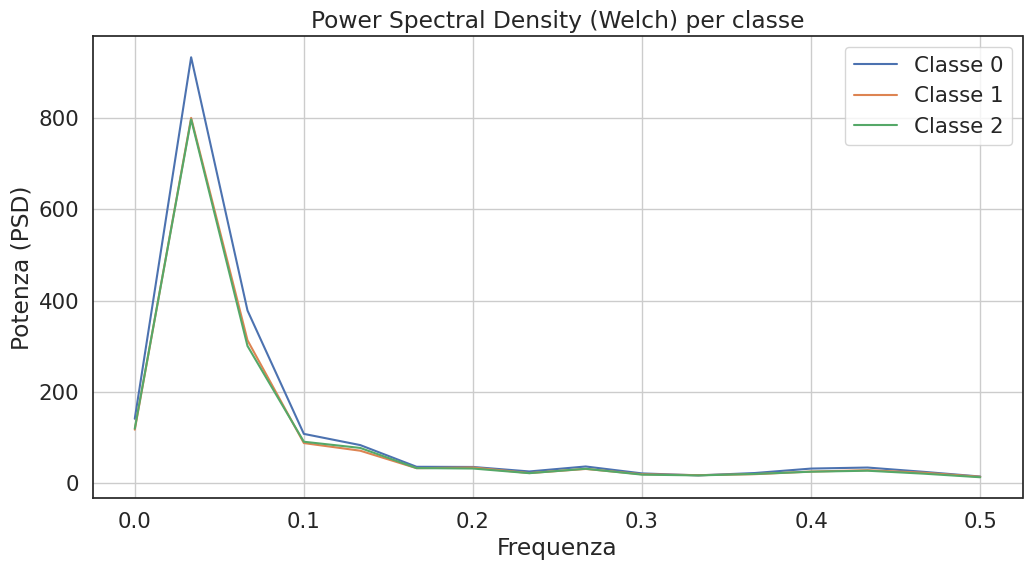

In [ ]:
plot_psd_by_class(df[column_names[9:39]].values, df['pain_level'].values, fs=1.0)

**Remark:** the similarity of the mean spectral densities across the three classes suggests that implementing a frequency-domain-based approach may not be advantageous.

# **Training and validation code**

The Neural Network used to solve the Classification Problem is made by:
- Three Convolutional 1D Layers
- Recurrent Layer with 1 hidden layer of size 256
- Attention layer
- Dense layer (Final classifier)

In [ ]:
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    Modified in order to handle Conv1d and GroupNorm layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM, nn.Conv1d, nn.GroupNorm, nn.BatchNorm1d)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [ ]:
#  @title Model

import torch
import torch.nn as nn
import torch.nn.functional as F

class Attention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)  # calcola score per ogni passo

    def forward(self, hidden_states):
        # hidden_states: [batch_size, seq_len, hidden_dim]
        scores = self.attn(hidden_states)           # [batch, seq_len, 1]
        weights = F.softmax(scores, dim=1)         # softmax sui passi
        context = torch.sum(weights * hidden_states, dim=1)  # somma pesata
        return context, weights

class RecurrentClassifier(nn.Module):
    """
    RNN/GRU/LSTM classifier con Conv1D iniziale e Attention finale.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',
            bidirectional=False,
            dropout_rate=0.2,
            conv_channels=96, # Changed from 64 to 96
            conv_kernel=9
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # --- Multi-scale Conv1D Block ---

        self.conv1 = nn.Conv1d(input_size, conv_channels, kernel_size=5, padding=2)
        self.conv2 = nn.Conv1d(input_size, conv_channels, kernel_size=7, padding=3)
        self.conv3 = nn.Conv1d(input_size, conv_channels, kernel_size=9, padding=4) # Changed padding from 4 to 3
        # self.bn = nn.BatchNorm1d(3*conv_channels)
        self.bn = nn.GroupNorm(1, 3*conv_channels)

        # --- RNN layer ---
        rnn_map = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}
        rnn_module = rnn_map[rnn_type]
        dropout_val = dropout_rate if num_layers > 1 else 0

        self.rnn = rnn_module(
            input_size=3*conv_channels,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # --- Attention layer ---
        self.attention = Attention(hidden_size * (2 if bidirectional else 1))

        # --- Final classifier ---
        self.classifier = nn.Linear(hidden_size * (2 if bidirectional else 1), num_classes)

    def forward(self, x):

        # --- Conv1D  ---
        x = x.transpose(1,2)
        x1 = F.relu(self.conv1(x))
        x2 = F.relu(self.conv2(x))
        x3 = F.relu(self.conv3(x))
        x = torch.cat([x1,x2,x3], dim=1)
        x = self.bn(x)
        x = x.transpose(1,2)
        # --- RNN ---
        rnn_out, hidden = self.rnn(x)

        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # --- Attention ---
        context, attn_weights = self.attention(rnn_out)

        # --- Classifier ---
        logits = self.classifier(context)
        return logits, attn_weights

In [ ]:
# @title Training function

def train_one_epoch(model, train_loader, criterion, optimizer, scaler, scheduler, device, l1_lambda=0, l2_lambda=0):
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits, _ = model(inputs) # Unpack the tuple here, ignoring attn_weights
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())


    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [ ]:
# @title Validation function

def validate_one_epoch(model, val_loader, criterion, device):
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits, _ = model(inputs) # Unpack the tuple here, ignoring attn_weights
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):

    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)

    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Adding sum of training and validation loss for overfitting monitoring
    writer.add_scalar("Loss/Sum", train_loss + val_loss, epoch)

    # Adding LR graph
    writer.add_scalar("LearningRate", optimizer.param_groups[0]['lr'], epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [ ]:
# @title Fit function

def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler,scheduler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=data_formattata):

  # Initialize metrics tracking
  training_history = {
      'train_loss': [], 'val_loss': [],
      'train_f1': [], 'val_f1': []
  }

  # Configure early stopping if patience is set
  if patience > 0:
      patience_counter = 0
      best_metric = float('-inf') if mode == 'max' else float('inf')
      best_epoch = 0

  print(f"Training {epochs} epochs...")

  # Main training loop: iterate through epochs
  for epoch in range(1, epochs + 1):

      # Forward pass through training data, compute gradients, update weights
      train_loss, train_f1 = train_one_epoch(
          model, train_loader, criterion, optimizer, scaler, scheduler, device, l1_lambda, l2_lambda
      )

      # Evaluate model on validation data without updating weights
      val_loss, val_f1 = validate_one_epoch(
          model, val_loader, criterion, device
      )

      # Store metrics for plotting and analysis
      training_history['train_loss'].append(train_loss)
      training_history['val_loss'].append(val_loss)
      training_history['train_f1'].append(train_f1)
      training_history['val_f1'].append(val_f1)

      # Write metrics to TensorBoard for visualization
      if writer is not None:
          log_metrics_to_tensorboard(
              writer, epoch, train_loss, train_f1, val_loss, val_f1, model
          )

      # Step scheduler after validation metrics are available
      if scheduler is not None:
          if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau) and evaluation_metric == "val_f1":
              scheduler.step(val_f1)
          elif isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau) and evaluation_metric == "val_loss":
              scheduler.step(val_loss)
          else:
              scheduler.step()


      # Print progress every N epochs or on first epoch
      if verbose > 0:
          if epoch % verbose == 0 or epoch == 1:
              print(f"Epoch {epoch:3d}/{epochs} | "
                  f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                  f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

      # Early stopping logic: monitor metric and save best model
      if patience > 0:
          current_metric = training_history[evaluation_metric][-1]
          is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

          if is_improvement:
              best_metric = current_metric
              best_epoch = epoch
              print(f"New best {evaluation_metric}: {best_metric:.4f} at epoch {best_epoch}")
              model_save_path = f"{models_dir}{experiment_name}_model.pt"
              os.makedirs(os.path.dirname(model_save_path), exist_ok=True)
              torch.save(model.state_dict(), model_save_path)
              patience_counter = 0
          else:
              patience_counter += 1
              if patience_counter >= patience:
                  print(f"Early stopping triggered after {epoch} epochs.")
                  break
      if writer is not None:
        log_metrics_to_tensorboard(
            writer, epoch, train_loss, train_f1, val_loss, val_f1, model
        )


  history_save_path = f"{models_dir}{experiment_name}_history.pt"
  os.makedirs(os.path.dirname(history_save_path), exist_ok=True)
  torch.save(training_history, history_save_path)
  # Restore best model weights if early stopping was used
  if restore_best_weights and patience > 0:
      model.load_state_dict(torch.load(f"{models_dir}{experiment_name}_model.pt"))
      print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

  # Save final model if no early stopping
  if patience == 0:
      model_save_path = f"{models_dir}{experiment_name}_model.pt"
      os.makedirs(os.path.dirname(model_save_path), exist_ok=True)
      torch.save(model.state_dict(), model_save_path)

  # Close TensorBoard writer
  if writer is not None:
    writer.flush()
    writer.close()

  model.eval()
  all_preds = []
  all_labels = []
  with torch.no_grad():
      for inputs, labels in val_loader:
          inputs = inputs.to(device)
          labels = labels.to(device)
          logits, _ = model(inputs)
          preds = logits.argmax(dim=1)
          all_preds.extend(preds.cpu().numpy())
          all_labels.extend(labels.cpu().numpy())

  # Confusion matrix creation
  cm = confusion_matrix(all_labels, all_preds)
  print("Confusion Matrix:")
  print(cm)

  # Confusion matrix visualization
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.xlabel('Predicted')
  plt.ylabel('True')
  plt.show()

  return model, training_history

# **Hyperparameter Tuning**

To do Hyperparameter tuning, we defined a function to perform k-Fold Cross-Validation, and one to do a grid search over a set of configurations of parameters

In [ ]:
# @title k-Fold Function

def k_shuffle_split_cross_validation_round_rnn(df, epochs, criterion, device,
                            k, batch_size, hidden_layers, hidden_size, learning_rate, scheduler_size, dropout_rate,
                            window_size, stride, rnn_type, bidirectional, n_val_users = 61, n_test_users=0,
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name=""):


    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}


    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=input_shape[1],
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Iterate through K random splits
    for split_idx in range(k):
        current_split_experiment_name = experiment_name + "/split_" + str(split_idx)

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        SEED = seed + split_idx

        train_loader, val_loader, min_train, max_train, class_weights = gran_loader(df, seed = SEED, window_size = window_size, stride = stride, batch_size = batch_size)

        print(f"class_weights type: {type(class_weights)}, dtype: {class_weights.dtype}")

        # Training utilities
        criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        model = RecurrentClassifier(
            input_size=input_shape[1],
            hidden_size=hidden_size,
            num_layers=hidden_layers,
            num_classes=num_classes,
            dropout_rate=dropout_rate,
            bidirectional=bidirectional,
            rnn_type=rnn_type
        ).to(device)
        model.load_state_dict(initial_state)


        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)
        scheduler = StepLR(optimizer, step_size=5, gamma=scheduler_size)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))


        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=split_scaler,
            scheduler = scheduler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=current_split_experiment_name
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}\u00B1{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores

In [ ]:
# @title Grid Search function

def grid_search_cv_rnn(df, param_grid, fixed_params, cv_params, experiment_name, cross_val = False, verbose=True):

    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = experiment_name+"_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_shuffle_split_cross_validation_round_rnn(
            df=df,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}±{fold_scores['std']:.4f}")

    return results, best_config, best_score


def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2='
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_': ''
    }


    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}'])
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(μ={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

# **MAIN**

Use of early stopping: ensuring the model stops training when validation accuracy stops improving for "patience" epochs, and the weights are restored to the best-performing epoch.

In [ ]:
# @title Single training function

def single_training(df, epochs, device,batch_size, hidden_layers, hidden_size, learning_rate,
    window_size, stride, rnn_type, bidirectional,dropout_rate, criterion, seed = 42, output_channels=20, bagging_splits=None, k=None, n_val_users=None,
    scheduler_name='step', scheduler_size=0.5, scheduler_wait=3,cos_period=10, eta_min=0, amplitude=1.0, mode='max',
    l1_lambda=0, l2_lambda=0,patience=0, restore_best_weights=True,writer=None, verbose=10, experiment_name=""):


        # Re-instantiate rnn_model with parameters from fixed_params (matching the saved checkpoint)
        # Using global RNN_TYPE and HIDDEN_SIZE to ensure consistency with saved 'lstm_batch256' model
        rnn_model = RecurrentClassifier(
            input_size=input_shape[1],
            hidden_size=hidden_size,
            num_layers=hidden_layers,
            num_classes=num_classes,
            dropout_rate=dropout_rate,
            bidirectional=bidirectional,
            rnn_type=rnn_type,
            conv_channels=output_channels
        ).to(device)
        recurrent_summary(rnn_model, input_size=input_shape)

        # Set up TensorBoard logging and save model architecture
        # log_path = os.path.join(logs_dir, f"{experiment_name_bag}_{int(time.time())}")
        log_path = os.path.join(logs_dir, experiment_name)
        writer = SummaryWriter(log_dir=log_path)
        x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
        writer.add_graph(rnn_model, x)

        train_loader, val_loader, min_train, max_train, class_weights = gran_loader(
                df, seed = seed,  n_val_users =  n_val_users, window_size = window_size, stride = stride,
                batch_size = batch_size)
        print(f"class_weights type: {type(class_weights)}, dtype: {class_weights.dtype}")

        # Training utilities
        # criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
        criterion = FocalLoss(alpha=class_weights.to(device), gamma=0.5)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # SCHEDULER SETTING
        if scheduler_name == 'plat':
          scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(                               # SCHEDULER MAXATO
                optimizer,
                mode= mode,       # 'max' se monitori F1, 'min' se monitori loss
                factor = scheduler_size,       # dimezza il lr
                patience = scheduler_wait,       # aspetta 3 epoch senza miglioramento
                min_lr=1e-4
            )
        elif scheduler_name == 'step':
          scheduler = StepLR(optimizer, step_size= scheduler_wait, gamma=scheduler_size)
        elif scheduler_name == 'cosine':
          scheduler = CosineAnnealingLR(optimizer, T_max= cos_period, eta_min=eta_min)
        elif scheduler_name == 'exp':
          scheduler = ExponentialLR(optimizer, gamma=scheduler_size)
        elif scheduler_name == 'hyb':
          scheduler = IbridCosineStepLR(optimizer, T_max= cos_period,
                                        step_size=scheduler_wait, gamma=scheduler_size,
                                        amplitude = amplitude, eta_min = eta_min)


        # Enable mixed precision training for GPU acceleration
        scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        rnn_model, training_history = fit(
            model=rnn_model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            scheduler = scheduler,
            restore_best_weights=restore_best_weights,
            device=device,
            writer=writer,
            verbose=verbose,
            experiment_name= experiment_name,
            patience=patience
            )

        return rnn_model, training_history, min_train, max_train



In [ ]:
# @title Bagging function

def bagging(df, epochs, criterion, device,
            k, batch_size, hidden_layers, hidden_size, learning_rate, scheduler_size, dropout_rate,
            window_size, stride, rnn_type, bidirectional,scheduler_wait, cos_period, eta_min, amplitude,
            output_channels=20,scheduler_name = 'step', n_val_users = 61, bagging_splits=5,
            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name=""):

    for idx in range(bagging_splits):
        print(f"Bagging split {idx+1}/{bagging_splits}")

        experiment_name_bag = experiment_name + f"/bag_{idx}"

        seed_bag = seed + idx

        # Re-instantiate rnn_model with parameters from fixed_params (matching the saved checkpoint)
        # Using global RNN_TYPE and HIDDEN_SIZE to ensure consistency with saved 'lstm_batch256' model
        rnn_model = RecurrentClassifier(
            input_size=input_shape[1],
            hidden_size=hidden_size,
            num_layers=hidden_layers,
            num_classes=num_classes,
            dropout_rate=dropout_rate,
            bidirectional=bidirectional,
            rnn_type=rnn_type,
            conv_channels=output_channels
        ).to(device)
        recurrent_summary(rnn_model, input_size=input_shape)

        # Set up TensorBoard logging and save model architecture
        # log_path = os.path.join(logs_dir, f"{experiment_name_bag}_{int(time.time())}")
        log_path = os.path.join(logs_dir, experiment_name_bag)
        writer = SummaryWriter(log_dir=log_path)
        x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
        writer.add_graph(rnn_model, x)

        train_loader, val_loader, min_train, max_train, class_weights = gran_loader(
                df, seed = seed_bag, window_size = window_size, stride = stride,
                batch_size = batch_size)
        print(f"class_weights type: {type(class_weights)}, dtype: {class_weights.dtype}")

        # Training utilities
        criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # SCHEDULER SETTING
        if scheduler_name == 'plat':
          scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(                               # SCHEDULER MAXATO
                optimizer,
                mode= mode,       # 'max' se monitori F1, 'min' se monitori loss
                factor = scheduler_size,       # dimezza il lr
                patience = scheduler_wait,       # aspetta 3 epoch senza miglioramento
                min_lr=1e-4
            )
        elif scheduler_name == 'step':
          scheduler = StepLR(optimizer, step_size= scheduler_wait, gamma=scheduler_size)
        elif scheduler_name == 'cosine':
          scheduler = CosineAnnealingLR(optimizer, T_max= cos_period, eta_min=eta_min)
        elif scheduler_name == 'exp':
          scheduler = ExponentialLR(optimizer, gamma=scheduler_size)
        elif scheduler_name == 'hyb':
          scheduler = IbridCosineStepLR(optimizer, T_max= cos_period,
                                        step_size=scheduler_wait, gamma=scheduler_size,
                                        amplitude = amplitude, eta_min = eta_min)


        # Enable mixed precision training for GPU acceleration
        scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        rnn_model, training_history = fit(
            model=rnn_model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            scheduler = scheduler,
            restore_best_weights=restore_best_weights,
            device=device,
            writer=writer,
            verbose=verbose,
            experiment_name= experiment_name_bag,
            patience=patience
            )

    return rnn_model, training_history, min_train, max_train


# **PARAMETER SETTINGS**

In [ ]:

experiment_name= "TRIAL_FRACOMPLETO"
experiment_name = experiment_name + '_' + data_formattata

UPLOAD = False           # Wheter to update the last model or not
CROSS_VAL = False        # Whether to perform K-fold cross-validation
GRID_SEARCH = False      # Whether to perform Grid-Search
BAGGING = False           # Whether to perform Bagging

# Bagging
BAGGING_SPLITS = 2

# Training
EPOCHS = 200              # Maximum epochs (increase to improve performance)
PATIENCE = 20             # Early stopping patience (increase to improve performance)
VERBOSE = 3               # Print frequency

# Optimisation
LEARNING_RATE = 0.001    # Learning rate
BATCH_SIZE = 256         # Batch size
WINDOW_SIZE = 40         # Input window size
STRIDE = 10               # Input stride

# Convolutional layer
OUTPUT_CHANNELS = 22

# Scheduler
SCHED_NAME = 'plat'
SCHEDULER_SIZE = 0.5
SCHEDULER_WAIT = 3
COS_PERIOD = 5
ETA_MIN = 1e-6
AMPLITUDE = 0.5

# Architecture
HIDDEN_LAYERS = 2         # Hidden layers
HIDDEN_SIZE =  128       # Neurons per layer
RNN_TYPE = 'LSTM'         # Type of RNN architecture
BIDIRECTIONAL = True     # Bidirectional RNN


# Regularisation
DROPOUT_RATE = 0.3        # Dropout probability
L1_LAMBDA = 0             # L1 penalty
L2_LAMBDA = 1e-4         # L2 penalty

# Cross-val params
K = 5                    # Number of splits (5 and 10 are considered good values)
N_VAL_USERS = 61         # Number of users for validation split

# Training utilities
# criterion = nn.CrossEntropyLoss()
# criterion = FocalLoss(alpha=class_weights, gamma=2)



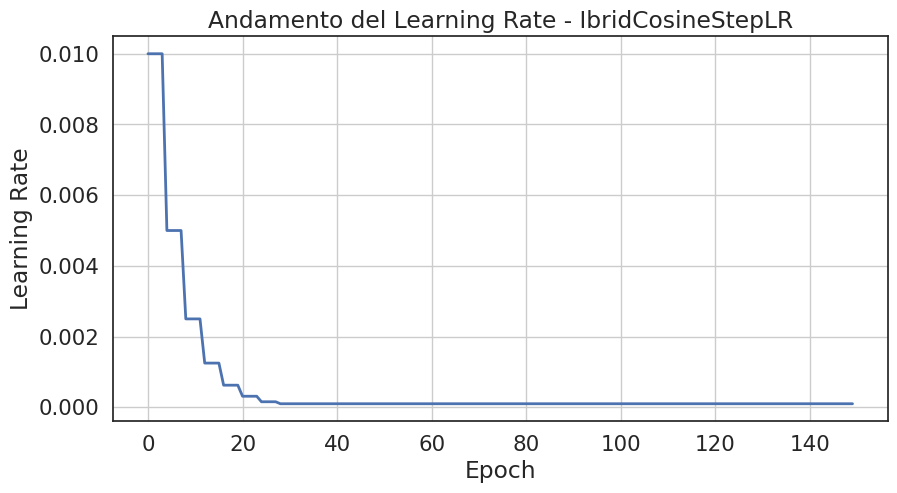

In [ ]:
# @title Preliminar LR shape check

# Allows to prevently detect non appropriate LR behaviour

optimizer = torch.optim.Adam([torch.zeros(1)], lr=0.01)

# Istanzia il tuo scheduler personalizzato
if SCHED_NAME == 'plat':
  scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=SCHEDULER_SIZE,
        patience=SCHEDULER_WAIT,
        min_lr=1e-4
    )
elif SCHED_NAME == 'step':
  scheduler = StepLR(optimizer, step_size= SCHEDULER_WAIT, gamma=SCHEDULER_SIZE)
elif SCHED_NAME == 'cosine':
  scheduler = CosineAnnealingLR(optimizer, T_max= COS_PERIOD, eta_min=ETA_MIN)
elif SCHED_NAME == 'exp':
  scheduler = ExponentialLR(optimizer, gamma=SCHEDULER_SIZE)
elif SCHED_NAME == 'hyb':
  scheduler = IbridCosineStepLR(optimizer, T_max= COS_PERIOD, step_size=SCHEDULER_WAIT, gamma=SCHEDULER_SIZE, amplitude = AMPLITUDE, eta_min = ETA_MIN)

# Numero di epoche da simulare
epochs = 150

# Lista per memorizzare LR
lrs = []

for epoch in range(epochs):
    optimizer.step()
    if SCHED_NAME == 'plat':
        scheduler.step(1)
    else:
        scheduler.step()
    lrs.append(scheduler.get_last_lr()[0])  # salva il LR corrente

# === Plot ===
plt.figure(figsize=(10,5))
plt.plot(range(epochs), lrs, linewidth=2)
plt.title("Andamento del Learning Rate - IbridCosineStepLR")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.grid(True)
plt.show()

## **Parameters loading and training logs**

In [ ]:
param_grid = {
      'batch_size': [64, 128, 256]
}

if CROSS_VAL == False:
  K=1
  if N_VAL_USERS < 61:
    N_VAL_USERS = 61


# Tutti i parametri base (che possono essere sia fissi che da cercare)
base_params = {
    'window_size': WINDOW_SIZE,
    'stride': STRIDE,
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'hidden_layers': HIDDEN_LAYERS,
    'hidden_size': HIDDEN_SIZE,
    'dropout_rate': DROPOUT_RATE,
    'l1_lambda': L1_LAMBDA,
    'l2_lambda': L2_LAMBDA,
    'rnn_type': RNN_TYPE,
    'bidirectional': BIDIRECTIONAL,
    'bagging_splits' : BAGGING_SPLITS,
    'scheduler_name' : SCHED_NAME,
    'scheduler_size': SCHEDULER_SIZE,
    'scheduler_wait':SCHEDULER_WAIT,
    'cos_period':COS_PERIOD,
    'eta_min' : ETA_MIN,
    'amplitude': AMPLITUDE,
    'output_channels':OUTPUT_CHANNELS
}

cv_params = {
    'epochs': EPOCHS,
    'criterion': criterion,
    'device': device,
    'k': K,
    'n_val_users': N_VAL_USERS,
    'patience': PATIENCE,
    'verbose': VERBOSE,
    'seed': SEED
}

# Se stai facendo Grid Search, togli quelli che sono già nel param_grid
if GRID_SEARCH == True:
    fixed_params = {k: v for k, v in base_params.items() if k not in param_grid.keys()}
else:
    fixed_params = base_params

print("Fixed params:", fixed_params)
print("Tuned params:", list(param_grid.keys()))

Fixed params: {'window_size': 40, 'stride': 10, 'batch_size': 256, 'learning_rate': 0.001, 'hidden_layers': 2, 'hidden_size': 128, 'dropout_rate': 0.3, 'l1_lambda': 0, 'l2_lambda': 0.0001, 'rnn_type': 'LSTM', 'bidirectional': True, 'bagging_splits': 2, 'scheduler_name': 'plat', 'scheduler_size': 0.5, 'scheduler_wait': 3, 'cos_period': 5, 'eta_min': 1e-06, 'amplitude': 0.5, 'output_channels': 22}
Tuned params: ['batch_size']


-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
conv1 (Conv1d)            [-1, 22, 40]                 4,092          
conv2 (Conv1d)            [-1, 22, 40]                 5,720          
conv3 (Conv1d)            [-1, 22, 40]                 7,348          
bn (GroupNorm)            [-1, 66, 40]                 132            
rnn (LSTM)                [[-1, 40, 256], [4, -1, 128]] 595,968        
classifier (Linear)       [-1, 3]                      771            
Total params: 614,031
Trainable params: 614,031
Non-trainable params: 0
-------------------------------------------------------------------------------
Training set shape: (118720, 41)
Validation set shape: (9760, 40)
class_weights type: <class 'torch.Tensor'>, dtype: torch.float32
Training 200 epochs...
Epoch   1/200 | Train: Loss=0.7971, F1 Score=0.5752 | Val: Loss=0.6594, F1 Score=0.4772
New best val_f1: 0.4772 a

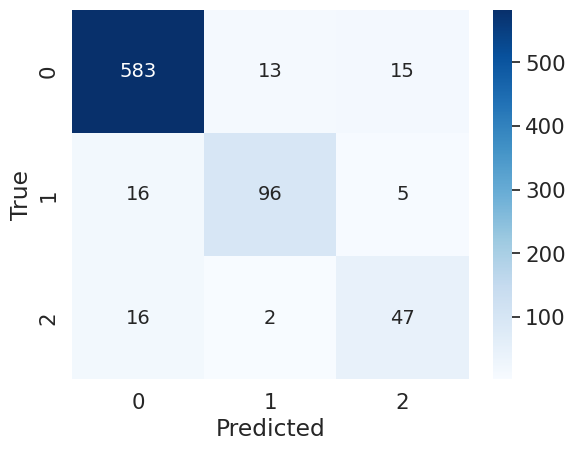

In [ ]:
if UPLOAD == True:
  rnn_model,_ = reload_model(experiment_name, device,
                 input_size=37, hidden_size=HIDDEN_SIZE, num_layers=HIDDEN_LAYERS,
                 num_classes=3, dropout_rate=DROPOUT_RATE,
                 bidirectional=BIDIRECTIONAL, rnn_type=RNN_TYPE)
elif GRID_SEARCH == True:
    # Execute search
    results, best_config, best_score = grid_search_cv_rnn(
        df=df,
        param_grid=param_grid,
        experiment_name = experiment_name,
        fixed_params=fixed_params,
        cv_params=cv_params
    )
    print(f"Best overall score: {best_score:.4f}")
    print(f"Best averall config: {best_config}")
    print("Retraining with best parameters")

elif CROSS_VAL == True:
  losses, metrics, best_scores = k_shuffle_split_cross_validation_round_rnn(
        df=df,
        experiment_name = experiment_name,
        **fixed_params,
        **cv_params
      )
elif BAGGING == True:
  rnn_model, training_history, min_train, max_train = bagging(
        df=df,
        experiment_name = experiment_name,
        **fixed_params,
        **cv_params
      )
else:
    rnn_model, training_history, min_train, max_train = single_training(
        df=df,
        experiment_name = experiment_name,
        **fixed_params,
        **cv_params
      )

In [ ]:
# Visualise results
if GRID_SEARCH == True and UPLOAD==False:
  plot_top_configurations_rnn(results, k_splits=K, top_n=5)

In [ ]:
# @title Tensorboard

# %tensorboard --logdir logs_dir


# **TEST**

In [ ]:
df_test = pd.read_csv('/content/drive/MyDrive/CHALLENGE 1/PiratePainDataset/pirate_pain_test.csv')

In [ ]:
# @title TEST PREPROCESSING

# Extraction of the values associated to the joints between 13 and 29
log_columns = [f'joint_{i}' for i in range(13, 30)]

# Log scale transformation
df_test[log_columns] = np.log(df_test[log_columns] + 1e-8)

column_names = ['sample_index', 'time']
column_names = column_names + [f'pain_survey_{str(i+1)}' for i in range(4)]
column_names = column_names + ['n_legs', 'n_hands', 'n_eyes']
column_names = column_names + [f'joint_{str(i).zfill(2)}' for i in range(31)]
column_names = column_names + [f'pain_level']

# Map activity names to integers in the training set
df_test['n_legs'] = df_test['n_legs'].map(legs_mapping)

# Map activity names to integers in the training set
df_test['n_hands'] = df_test['n_hands'].map(hands_mapping)

# Map activity names to integers in the training set
df_test['n_eyes'] = df_test['n_eyes'].map(eyes_mapping)

df_test = df_test.drop(['joint_30'], axis = 1)

#Convert int64 type column  to int32 data type
for column in column_names[:9]:
    df_test[column] = df_test[column].astype(np.int32)

#Convert float64 type column  to float32 data type
for column in column_names[9:39]:
    df_test[column] = df_test[column].astype(np.float32)

# Define the columns to be normalised
scale_columns = column_names[9:39]

# Calculate the minimum and maximum values from the training data only
mins = min_train
maxs = max_train

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the test set
    df_test[column] = (df_test[column] - mins[column]) / (maxs[column] - mins[column])

# Display the first five rows of the training DataFrame
print(df_test.shape)

(211840, 39)


In [ ]:
# Define a function to build sequences from the dataset with sample indices returned
def build_test_sequences(df, window, stride):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences, their corresponding labels, and sample indices
    dataset = []
    sample_indices = []

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][column_names[2:39]].values

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        if padding_len != window:  # if temp is already divisible by window, no padding
            padding = np.zeros((padding_len, 37), dtype='float32')
            temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels and sample indices
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            sample_indices.append(id)  # keep track of sample index for voting
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    sample_indices = np.array(sample_indices)

    return dataset, sample_indices


def voting(predictions_with_indices):

    # Crea un DataFrame temporaneo con colonne 'index' e 'prediction'
    df = pd.DataFrame(predictions_with_indices, columns=['index', 'prediction'])

    # Per ogni index, prendi la predizione più frequente (mode)
    voted_df = df.groupby('index')['prediction'].agg(lambda x: x.mode()[0]).reset_index()

    # Converti il DataFrame votato in numpy array e restituisci
    return voted_df.values

In [ ]:
# experiment_name = "FRA__GRU__1LAYER"

In [ ]:
# Generate sequences and labels for the training set
X_test, indexes = build_test_sequences(df_test, WINDOW_SIZE, STRIDE)

test_ds = TensorDataset(torch.from_numpy(X_test).float())
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

if BAGGING:
    print("Testing BAGGING")
    all_preds = []
    for idx in range(BAGGING_SPLITS):
        model_path = f"/content/drive/MyDrive/CHALLENGE 1/models/{experiment_name}/bag_{idx}_model.pt"
        model = RecurrentClassifier(
            input_size=37,
            hidden_size=HIDDEN_SIZE,
            num_layers=HIDDEN_LAYERS,
            num_classes=num_classes,
            dropout_rate=DROPOUT_RATE,
            bidirectional=BIDIRECTIONAL,
            rnn_type=RNN_TYPE
        ).to(device)

        model.load_state_dict(torch.load(model_path, map_location=device))
        model.eval()

        preds = []
        with torch.no_grad():
            for inputs in test_loader:
                inputs = inputs[0].to(device)  # Accedi al tensor singolo
                logits, _ = model(inputs) # Unpack the tuple here, ignoring attn_weights
                preds.append(logits.softmax(dim=1).cpu().numpy())

        bag_preds = np.vstack(preds)
        all_preds.append(bag_preds)

    # Media delle probabilità tra i modelli
    final_probs = np.mean(all_preds, axis=0)
    windows_predictions = np.argmax(final_probs, axis=1)

    # Combina con gli indici per il voting
    predictions_with_indices = np.column_stack((indexes, windows_predictions))
    test_predictions = voting(predictions_with_indices)

else:
    rnn_model.eval()
    windows_predictions = []

    with torch.no_grad():
        for inputs in test_loader:
            inputs = inputs[0].to(device) # Access the single tensor from the tuple
            logits, _ = rnn_model(inputs) # Unpack the tuple here, ignoring attn_weights
            preds = logits.argmax(dim=1).cpu().numpy()
            windows_predictions.append(preds)

    windows_predictions = np.concatenate(windows_predictions, axis=0)
    predictions_with_indices = np.column_stack((indexes, windows_predictions))
    test_predictions = voting(predictions_with_indices)

In [ ]:
pd.Series(windows_predictions).value_counts()

,count
0,11448
1,3880
2,1884


In [ ]:
# @title REVERSE MAPPING
# Initialise a dictionary to count occurrences of each activity in the training set
reverse_mapping = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2
}

reverse_pain_level_mapping = {v: k for k, v in pain_level_mapping.items()}

# Map the numerical predictions back to their original string labels
test_predictions_labels = np.array([reverse_pain_level_mapping[pred[1]] for pred in test_predictions])

pd.Series(test_predictions_labels).value_counts()

# Get the unique sample_index values from the original test dataset
unique_test_sample_indices = df_test['sample_index'].unique()

# Ensure the number of predictions matches the number of unique sample indices
if len(test_predictions_labels) != len(unique_test_sample_indices):
    print("Warning: Number of predictions does not match number of unique sample indices.")

# Create a DataFrame to store the results
submission_df = pd.DataFrame({
    'Id': unique_test_sample_indices,
    'Pain_Level': test_predictions_labels
})

# Format the 'Id' column as a three-digit string
submission_df['Id'] = submission_df['Id'].apply(lambda x: str(x).zfill(3))

# Display the first few rows of the result
pd.Series(submission_df['Pain_Level']).value_counts()


,count
Pain_Level,
no_pain,999
low_pain,225
high_pain,100


In [ ]:
# Rename columns to match submission format
submission_df = submission_df.rename(columns={'Id': 'sample_index', 'Pain_Level': 'label'})

# Display the first few rows of the formatted submission DataFrame
display(submission_df.head())

# Save the submission DataFrame to a CSV file with the specified format
submission_df.to_csv('/content/drive/MyDrive/CHALLENGE 1/submissions/submission_'+experiment_name+'.csv', index=False)
print("Submission file updated with the correct format and saved successfully!")

,sample_index,label
0,000,high_pain
1,001,no_pain
2,002,no_pain
3,003,no_pain
4,004,no_pain


Submission file updated with the correct format and saved successfully!
